<a href="https://colab.research.google.com/github/sara-velmont/Proyectos/blob/main/Series_de_tiempo_Proyecto_P1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Código implementado**



#Carga de archivos

In [ ]:
from google.colab import files
files.upload()  # Subir kaggle.json


Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"saravlezmontesinos","key":"d13d676303e68de1b6d44826071e1c0f"}'}

In [ ]:
import os
import zipfile

# Crear carpeta kaggle y mover el archivo ahí
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Instalar la API de Kaggle
!pip install -q kaggle


In [ ]:
# Dataset 1: Temperaturas diarias
!kaggle datasets download -d sohier/daily-temperature-of-major-cities

# Dataset 2: Consumo energético por hora
!kaggle datasets download -d robikscube/hourly-energy-consumption

# Dataset 3: Pasajeros aéreos mensuales
!kaggle datasets download -d shubhendra7/air-passengers



403 Client Error: Forbidden for url: https://www.kaggle.com/api/v1/datasets/metadata/sohier/daily-temperature-of-major-cities
Dataset URL: https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption
License(s): CC0-1.0
  0% 0.00/11.4M [00:00<?, ?B/s]
100% 11.4M/11.4M [00:00<00:00, 738MB/s]
403 Client Error: Forbidden for url: https://www.kaggle.com/api/v1/datasets/metadata/shubhendra7/air-passengers


In [ ]:
# Asumiendo que ya subiste kaggle.json y configuraste la API:
!kaggle datasets download -d robikscube/hourly-energy-consumption
!kaggle datasets download -d robervalt/sunspots


Dataset URL: https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption
License(s): CC0-1.0
hourly-energy-consumption.zip: Skipping, found more recently modified local copy (use --force to force download)
Dataset URL: https://www.kaggle.com/datasets/robervalt/sunspots
License(s): CC0-1.0
  0% 0.00/22.4k [00:00<?, ?B/s]
100% 22.4k/22.4k [00:00<00:00, 60.8MB/s]


In [ ]:
!kaggle datasets download -d ritheshkrish/beer-production

403 Client Error: Forbidden for url: https://www.kaggle.com/api/v1/datasets/metadata/ritheshkrish/beer-production


In [ ]:
from statsmodels.datasets import co2

# Cargar y procesar serie CO2 correctamente
data_co2 = co2.load_pandas().data
data_co2 = data_co2.ffill()                   # Sin warning
data_co2 = data_co2.resample("ME").mean()     # "ME" = Month-End



In [ ]:
!ls

hourly-energy-consumption.zip  sample_data  sunspots.zip


In [ ]:
import zipfile

zip_files = [
    "sunspots.zip",
    "hourly-energy-consumption.zip",
]

for zf in zip_files:
    with zipfile.ZipFile(zf, 'r') as zip_ref:
        zip_ref.extractall("data")


#Visualización de serie

/tmp/ipython-input-9-1549530362.py:7: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_energy = df_energy.set_index("Datetime").resample("M").mean()["PJME_MW"]
/tmp/ipython-input-9-1549530362.py:11: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_sunspots = df_sunspots.set_index("Date").resample("M").mean()["Monthly Mean Total Sunspot Number"]
/tmp/ipython-input-9-1549530362.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


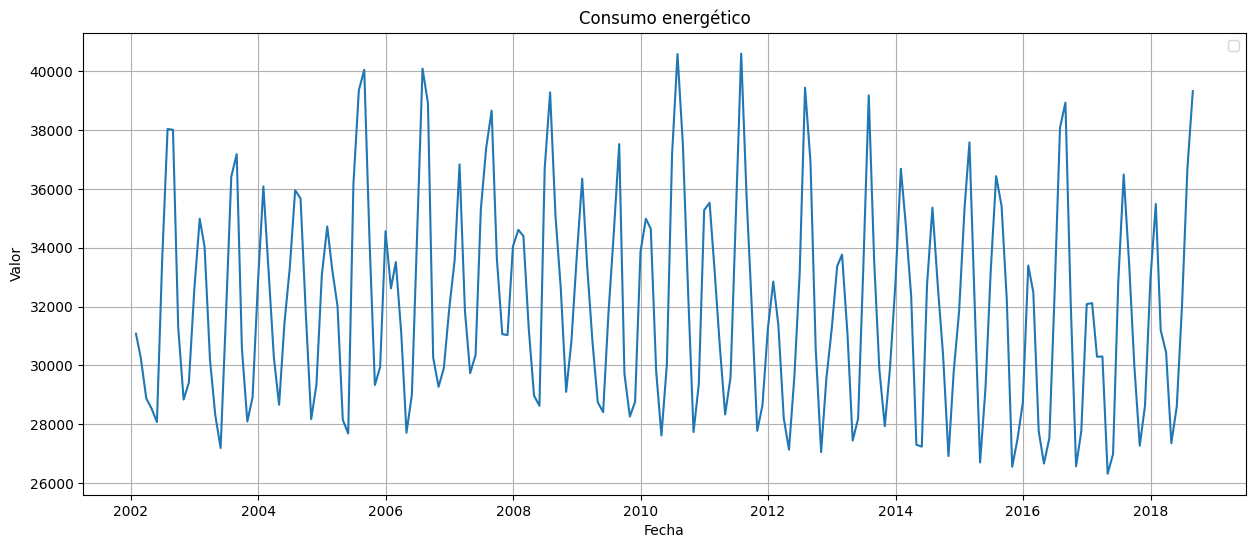

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


# Consumo energético (resample a mensual)
df_energy = pd.read_csv("data/PJME_hourly.csv", parse_dates=["Datetime"])
df_energy = df_energy.set_index("Datetime").resample("M").mean()["PJME_MW"]

# Dataset 2: Manchas solares
df_sunspots = pd.read_csv("data/Sunspots.csv", parse_dates=["Date"])
df_sunspots = df_sunspots.set_index("Date").resample("M").mean()["Monthly Mean Total Sunspot Number"]

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
plt.plot(df_energy)
#plt.plot(df_sunspots, label="Manchas solares")
plt.title("Consumo energético")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.legend()
plt.grid(True)
plt.show()



/tmp/ipython-input-10-2213531739.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


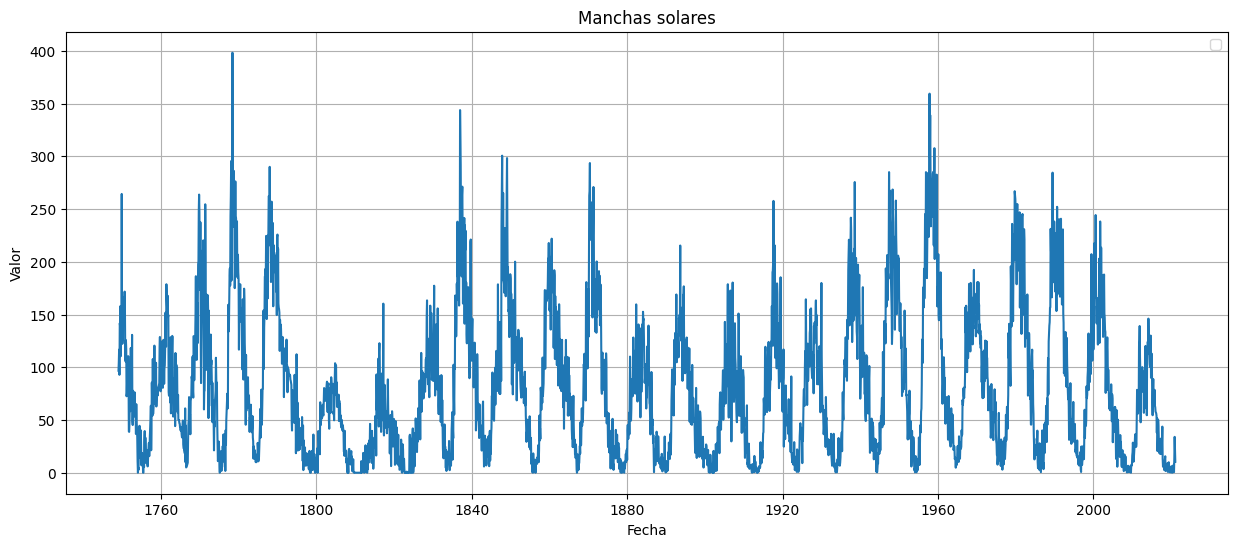

In [ ]:
plt.figure(figsize=(15, 6))
plt.plot(df_sunspots)
plt.title("Manchas solares")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.legend()
plt.grid(True)
plt.show()

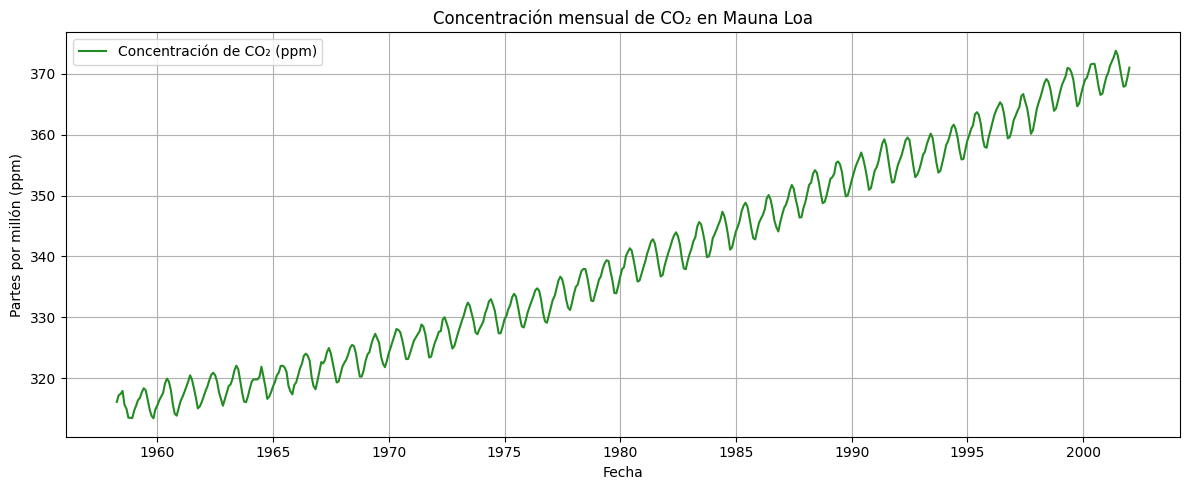

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(data_co2, color='forestgreen', label='Concentración de CO₂ (ppm)')
plt.title('Concentración mensual de CO₂ en Mauna Loa')
plt.xlabel('Fecha')
plt.ylabel('Partes por millón (ppm)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#Análisis

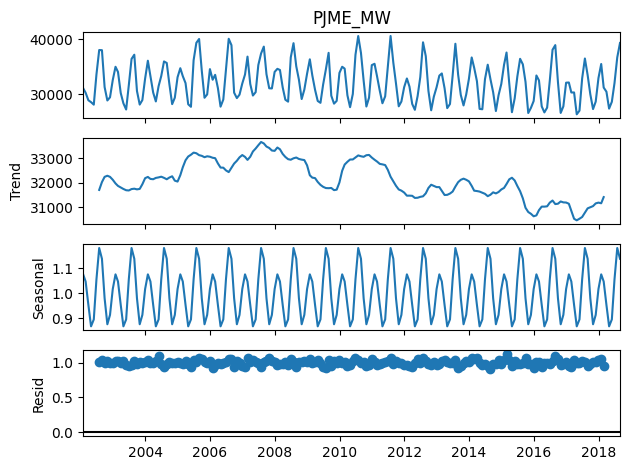

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
# Eliminar valores nulos (seasonal_decompose no los tolera)
df_energy = df_energy.dropna()

# Descomposición estacional (multiplicativa o aditiva, según lo que se ajuste mejor)
decomp = seasonal_decompose(df_energy, model="multiplicative")

# Mostrar resultados
decomp.plot()
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

serie = df_energy

# Aplicar prueba ADF
result = adfuller(serie)

# Imprimir resultados
print("ADF Statistic:", result[0])
print("p-value:", result[1])
for key, value in result[4].items():
    print(f"Critical Value ({key}): {value}")


ADF Statistic: -1.9536484960701135
p-value: 0.3072588423798128
Critical Value (1%): -3.466398230774071
Critical Value (5%): -2.8773796387256514
Critical Value (10%): -2.575213838610586


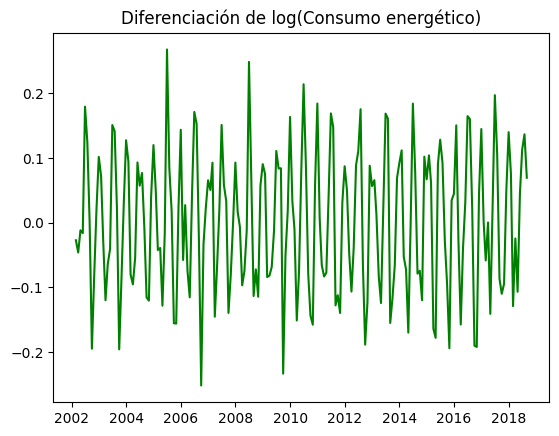

In [ ]:
import numpy as np
# Asegurarse de que no haya valores <= 0
df_energy_log = np.log(df_energy[df_energy > 0])

# Diferencia del logaritmo
diff_log_energy = df_energy_log.diff().dropna()

# Graficar
plt.plot(diff_log_energy, color='green')
plt.title("Diferenciación de log(Consumo energético)")
plt.show()

In [ ]:
serie = diff_log_energy

# Aplicar prueba ADF
result = adfuller(serie)

# Imprimir resultados
print("ADF Statistic:", result[0])
print("p-value:", result[1])
for key, value in result[4].items():
    print(f"Critical Value ({key}): {value}")

ADF Statistic: -6.006162679674739
p-value: 1.6136430673864723e-07
Critical Value (1%): -3.466398230774071
Critical Value (5%): -2.8773796387256514
Critical Value (10%): -2.575213838610586


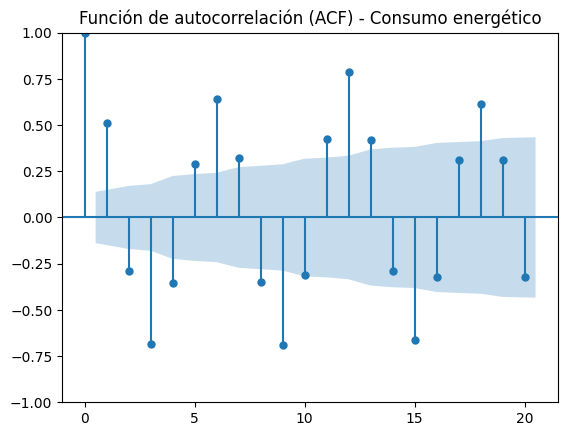

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
# Asegúrate de que no haya valores nulos
serie = df_energy.dropna()

# Graficar ACF hasta 20 rezagos
plot_acf(serie, lags=20)
plt.title("Función de autocorrelación (ACF) - Consumo energético")
plt.show()

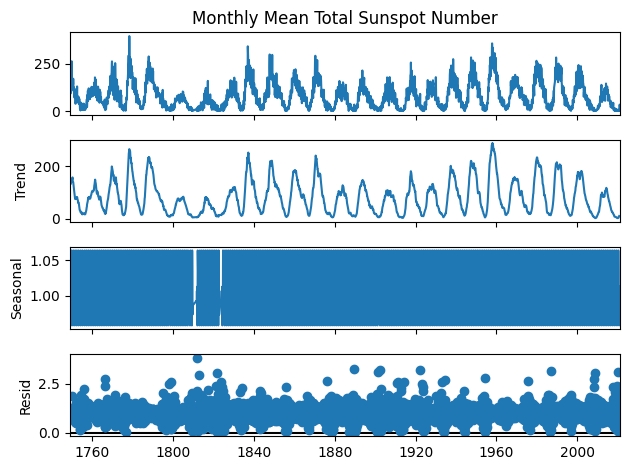

In [ ]:
# Eliminar valores nulos (seasonal_decompose no los tolera)
df_sunspots = df_sunspots.dropna()
df_sunspots = df_sunspots[df_sunspots > 0]


# Descomposición estacional (multiplicativa o aditiva, según lo que se ajuste mejor)
decomp = seasonal_decompose(df_sunspots, model="multiplicative", period=11)

# Mostrar resultados
decomp.plot()
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

serie = df_sunspots

# Aplicar prueba ADF
result = adfuller(serie)

# Imprimir resultados
print("ADF Statistic:", result[0])
print("p-value:", result[1])
for key, value in result[4].items():
    print(f"Critical Value ({key}): {value}")

ADF Statistic: -10.576277785254248
p-value: 7.092069853618766e-19
Critical Value (1%): -3.4324151955975806
Critical Value (5%): -2.8624524771395365
Critical Value (10%): -2.5672557325337633


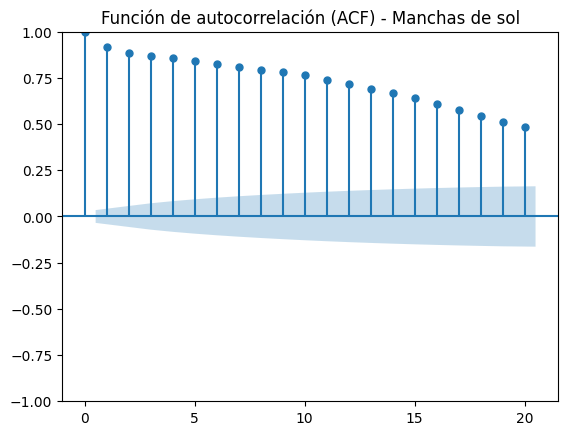

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
serie = df_sunspots.dropna()

# Graficar ACF hasta 20 rezagos
plot_acf(serie, lags=20)
plt.title("Función de autocorrelación (ACF) - Manchas de sol")
plt.show()

/tmp/ipython-input-24-4066604807.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  data_co2.index.freq = 'M'


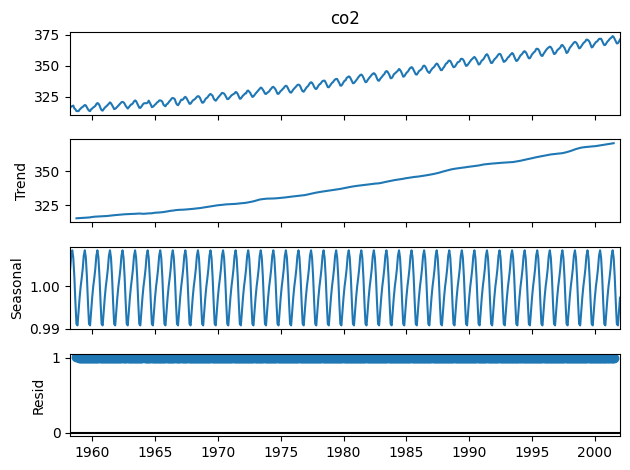

In [ ]:
# Verificar que el índice tenga frecuencia explícita
data_co2.index.freq = 'M'

# Descomposición aditiva (puede ser multiplicativa si no hay ceros)
decomp = seasonal_decompose(data_co2["co2"], model="multiplicative", period=12)
decomp.plot()
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

serie = data_co2["co2"]

# Aplicar prueba ADF
result = adfuller(serie)

# Imprimir resultados
print("ADF Statistic:", result[0])
print("p-value:", result[1])
for key, value in result[4].items():
    print(f"Critical Value ({key}): {value}")

ADF Statistic: 2.1401057237719256
p-value: 0.9988294944044314
Critical Value (1%): -3.4432372923913124
Critical Value (5%): -2.86722383510113
Critical Value (10%): -2.5697972702806613


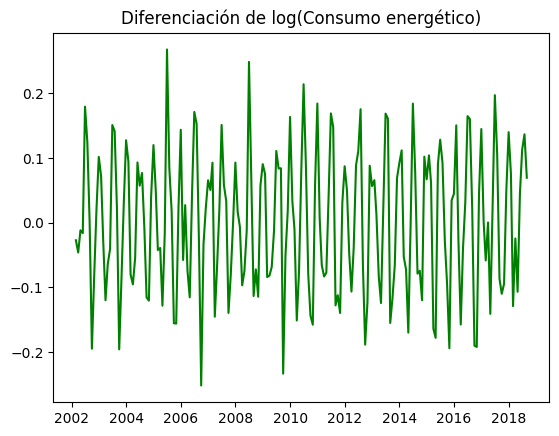

In [ ]:
# Asegurarse de que no haya valores <= 0
df_energy_log = np.log(df_energy[df_energy > 0])

# Diferencia del logaritmo
diff_log_energy = df_energy_log.diff().dropna()

# Graficar
plt.plot(diff_log_energy, color='green')
plt.title("Diferenciación de log(Consumo energético)")
plt.show()

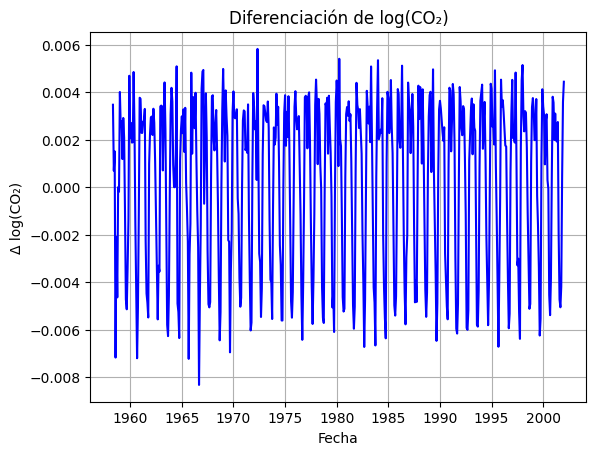

In [ ]:
co2_log = np.log(data_co2["co2"][data_co2["co2"] > 0])

# Diferenciación del logaritmo
diff_log_co2 = co2_log.diff().dropna()

# Graficar
plt.plot(diff_log_co2, color='blue')
plt.title("Diferenciación de log(CO₂)")
plt.xlabel("Fecha")
plt.ylabel("Δ log(CO₂)")
plt.grid(True)
plt.show()

In [ ]:
# Aplicar prueba ADF
result = adfuller(diff_log_co2)

# Imprimir resultados
print("ADF Statistic:", result[0])
print("p-value:", result[1])
for key, value in result[4].items():
    print(f"Critical Value ({key}): {value}")

ADF Statistic: -5.001096088077385
p-value: 2.2082568160261063e-05
Critical Value (1%): -3.44336554668393
Critical Value (5%): -2.867280279529963
Critical Value (10%): -2.5698273512400744


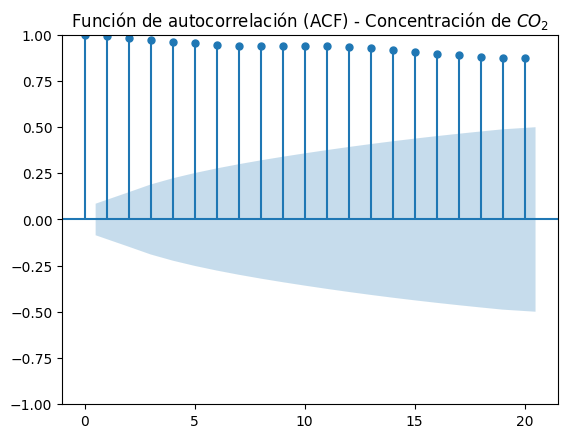

In [ ]:
# Graficar ACF hasta 20 rezagos
plot_acf(data_co2, lags=20)
plt.title("Función de autocorrelación (ACF) - Concentración de $CO_2$")
plt.show()